In [ ]:
!pip install opencv-python matplotlib requests

Image loaded successfully!
Image shape: (4000, 3000, 3)


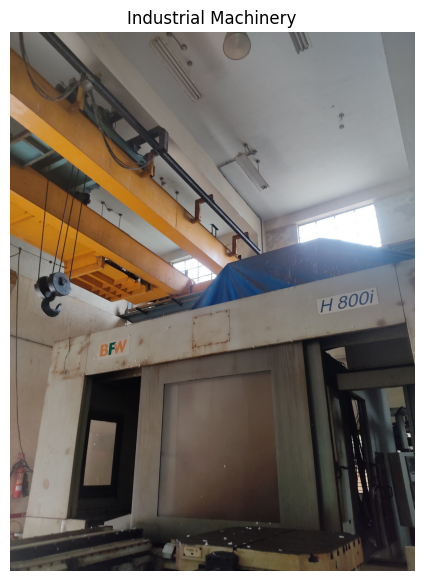

In [10]:
import requests
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_url = "https://commons.wikimedia.org/wiki/Special:Redirect/file/Machinery_in_industry.jpg"

response = requests.get(
    image_url,
    headers={
        "User-Agent": "Mozilla/5.0"
    },
    allow_redirects=True
)

image_array = np.frombuffer(response.content, np.uint8)
image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

if image is None:
    print("Image could not be decoded")
else:
    print("Image loaded successfully!")
    print("Image shape:", image.shape)

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 7))
    plt.imshow(image_rgb)
    plt.title("Industrial Machinery")
    plt.axis("off")
    plt.show()

In [ ]:


if image is not None:

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


    # Sobel X
    sobel_x = cv2.Sobel(
        gray,
        cv2.CV_64F,
        1,
        0,
        ksize=3
    )

    # Sobel Y

    sobel_y = cv2.Sobel(
        gray,
        cv2.CV_64F,
        0,
        1,
        ksize=3
    )

    # Convert to 8-bit
    sobel_x = cv2.convertScaleAbs(sobel_x)
    sobel_y = cv2.convertScaleAbs(sobel_y)

    # Combine Sobel X and Y
    sobel_combined = cv2.addWeighted(
        sobel_x, 0.5,
        sobel_y, 0.5,
        0
    )

    # Canny

    canny = cv2.Canny(
        gray,
        50,
        150
    )



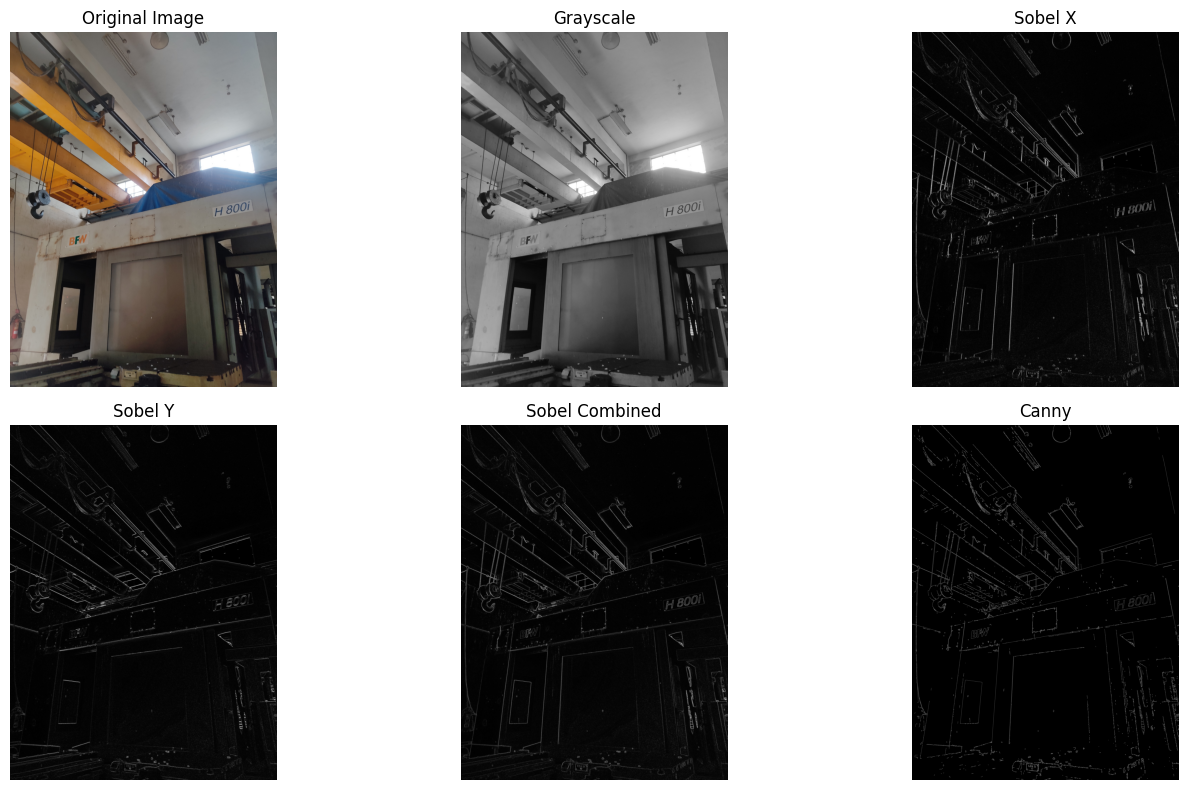

In [ ]:

    # Display

    plt.figure(figsize=(15, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(sobel_x, cmap="gray")
    plt.title("Sobel X")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(sobel_y, cmap="gray")
    plt.title("Sobel Y")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(sobel_combined, cmap="gray")
    plt.title("Sobel Combined")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(canny, cmap="gray")
    plt.title("Canny")
    plt.axis("off")

    plt.tight_layout()
    plt.show()